

---



---


# Multi-class Semantic Segmentation on the PanNuke Histological Dataset
---



---



## % Libraries - Imports

In [1]:
import os
import random
import sys

import numpy as np
import torch
from torch.utils.data import DataLoader, Subset

import matplotlib
import matplotlib.pyplot as plt
import torchvision

In [2]:
# double-check the installed versions of the key libraries
print(f"numpy version:        {np.__version__}")
print(f"torch version:         {torch.__version__}")
print(f"torchvision version:   {torchvision.__version__}")
print(f"matplotlib version:    {matplotlib.__version__}")


numpy version:        2.1.3
torch version:         2.11.0+cu130
torchvision version:   0.26.0+cu130
matplotlib version:    3.10.0


## % Mount Google drive

In [3]:
# mount Google Drive when running on Colab, otherwise use the local project folder
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/Deep_learning_course/Final_project/PanNuke"
except ImportError:
    PROJECT_DIR = os.getcwd()   # running locally, from the project folder

print("PROJECT_DIR:", PROJECT_DIR)

Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/Colab Notebooks/Deep_learning_course/Final_project/PanNuke


In [4]:
# import the functions/classes that were moved into .py files
# (the .py files are next to data_root/ in the project folder)
sys.path.insert(0, PROJECT_DIR)

from pannuke_dataset import *
from pannuke_utils import *
from model_simple_unet2 import SimpleUNet2

### --- Load data - PanNuke dataset - Fold1 ---
PanNuke Dataset for Nuclei Instance Segmentation and Classification - https://huggingface.co/datasets/RationAI/PanNuke

In [5]:
# load the PanNuke Fold1 images and their per-category instance masks
images = np.load(PROJECT_DIR + "/data_root/images.npy")
masks = np.load(PROJECT_DIR + "/data_root/masks.npy")

# sanity-check the loaded array shapes and dtypes
print("images shape:", images.shape, "images dtype:", images.dtype)
print("masks shape:", masks.shape, "masks dtype:", masks.dtype)

images shape: (2656, 256, 256, 3) images dtype: float64
masks shape: (2656, 256, 256, 6) masks dtype: float64


# SimpleUnet2 = DATA Augmentation + Dropout
Introducing the dropout technique into our SimpleUnet model -> SimpleUNet2

## % CONFIGURATION + Parameters setting + Data preparation for model training

In [6]:
# --- CONFIGURATION ---
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 64
LEARNING_RATE = 0.0005
NUM_EPOCHS = 120
VAL_SPLIT = 0.15
TEST_SPLIT = 0.15
CHECKPOINT_DIR = PROJECT_DIR + '/data_root/checkpoints_SimpleUnet2'

# fix all RNG seeds so the run is reproducible
SEED = 54
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.backends.cudnn.deterministic = True

# make sure the checkpoint folder exists
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

### --- DATA augmentation - for better generalization ---

In [7]:
# rebuild the dataset for this run, now with augmentation enabled
# two views of the same data: augmented for training, clean for validation/test
train_full_dataset = PanNukeDataset(images, masks, augment=True)
eval_full_dataset  = PanNukeDataset(images, masks, augment=False)

Dataset ready: 2656 samples
Dataset ready: 2656 samples


### --- Training/Validation/Test data creation ---

In [8]:
# re-split into train/val/test (fresh shuffle, same ratios as before)
n = len(train_full_dataset)
indices = list(range(n))
# shuffle before splitting so train/val/test are randomly sampled
random.shuffle(indices)

# compute split sizes from the configured ratios
n_val = int(n * VAL_SPLIT)
n_test = int(n * TEST_SPLIT)

# slice the shuffled indices into val / test / train
val_idx = indices[:n_val]
test_idx = indices[n_val:n_val + n_test]
train_idx = indices[n_val + n_test:]

print(f"Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}")

Train: 1860 | Val: 398 | Test: 398


In [9]:
# wrap each split's indices into a Subset, then into a DataLoader for batching
# only the training split reads from the augmented dataset
train_dataset = Subset(train_full_dataset, train_idx)
val_dataset = Subset(eval_full_dataset, val_idx)
test_dataset = Subset(eval_full_dataset, test_idx)

# only shuffle the training loader; keep val/test order fixed
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

### --- Model + optimizer - SimpleUNet2 ---

In [10]:
# create the (dropout) model and optimizer for this run
model_SimpleUNet2 = SimpleUNet2(num_classes=6).to(DEVICE)

optimizer_SimpleUNet2 = torch.optim.Adam(model_SimpleUNet2.parameters(), lr=LEARNING_RATE)

### --- Train SimpleUnet2 ---

In [ ]:
# training loop for SimpleUNet2 (dropout + augmentation)
print("Starting Training...")

# track loss/Dice history and keep the best checkpoint by validation Dice
history = {"train_loss": [], "train_dice": [], "val_loss": [], "val_dice": []}
best_val_dice = 0.0

for epoch in range(NUM_EPOCHS):
    # 1. Train
    train_loss, train_dice = train_model(model = model_SimpleUNet2,
                             training_data = train_loader,
                             num_classes=6,
                             optimizer = optimizer_SimpleUNet2)

    # 2. Validate
    val_loss, val_dice = validate_model(model = model_SimpleUNet2,
                                        validation_data = val_loader,
                                        num_classes=6)

    # 3. Store for plotting later
    history["train_loss"].append(train_loss)
    history["train_dice"].append(train_dice)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)

    # 4. Print Stats
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
          f"||| Train Loss: {train_loss:.4f} | Train Dice: {train_dice:.4f} "
          f"||| Val Loss: {val_loss:.4f} | Val Dice: {val_dice:.4f}")

    # checkpoint whenever validation Dice improves
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        checkpoint_path = os.path.join(CHECKPOINT_DIR, f'SimpleUnet2_{epoch}.pth')
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model_SimpleUNet2.state_dict(),
            'optimizer_state_dict': optimizer_SimpleUNet2.state_dict(),
            'val_dice': val_dice
        }, checkpoint_path)
        print(f"   >>> Improvement! Saving model (Dice: {val_dice:.4f})")

print(f"\nTraining Complete. Best Validation Dice: {best_val_dice:.4f}")

Starting Training...
Epoch [1/120] ||| Train Loss: 0.8831 | Train Dice: 0.1611 ||| Val Loss: 0.8762 | Val Dice: 0.1823
   >>> Improvement! Saving model (Dice: 0.1823)
Epoch [2/120] ||| Train Loss: 0.8395 | Train Dice: 0.2344 ||| Val Loss: 0.8335 | Val Dice: 0.2612
   >>> Improvement! Saving model (Dice: 0.2612)
Epoch [3/120] ||| Train Loss: 0.8040 | Train Dice: 0.2881 ||| Val Loss: 0.7801 | Val Dice: 0.2880
   >>> Improvement! Saving model (Dice: 0.2880)
Epoch [4/120] ||| Train Loss: 0.7852 | Train Dice: 0.3021 ||| Val Loss: 0.7790 | Val Dice: 0.2934
   >>> Improvement! Saving model (Dice: 0.2934)
Epoch [5/120] ||| Train Loss: 0.7558 | Train Dice: 0.3305 ||| Val Loss: 0.7329 | Val Dice: 0.3418
   >>> Improvement! Saving model (Dice: 0.3418)
Epoch [6/120] ||| Train Loss: 0.7354 | Train Dice: 0.3459 ||| Val Loss: 0.7252 | Val Dice: 0.3548
   >>> Improvement! Saving model (Dice: 0.3548)
Epoch [7/120] ||| Train Loss: 0.7161 | Train Dice: 0.3567 ||| Val Loss: 0.6935 | Val Dice: 0.3671
   >>

### --- Plot the progress ---

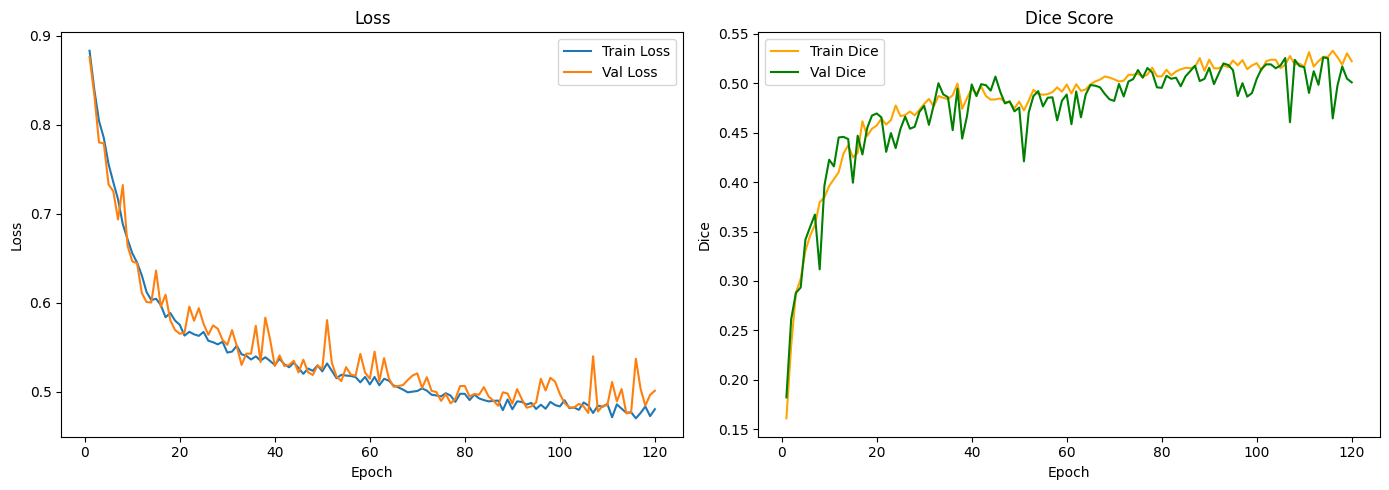

In [ ]:
# plot loss/Dice curves for this run
epochs = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
ax1.plot(epochs, history["train_loss"], label="Train Loss")
ax1.plot(epochs, history["val_loss"], label="Val Loss")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()

# Dice plot
ax2.plot(epochs, history["train_dice"], label="Train Dice", color="orange")
ax2.plot(epochs, history["val_dice"], label="Val Dice", color="green")
ax2.set_title("Dice Score")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice")
ax2.legend()

plt.tight_layout()
plt.show()

### --- Conclusion ---

After finishing the training on our SimpleUNet2 model we can see the following:

**Loss graph:**
*   Train Loss decreases smoothly and steadily
*   Val Loss decreases with only small fluctuations
*   The decrease slows down after about the 90th epoch, but does not stop



---
**Dice graph:**
*   Train Dice increases nicely
*   Val Dice increases nicely with some fluctuations - we have to take into consideration that we calculate a mean Dice score for all 6 classes
*   The increase slows down after about the 90th epoch (Val Dice around 0.51 - 0.52), but does not stop

---
*   => model generalizes well
*   => no overfitting
*   => the gap between Train and Val Dice stays small (mostly below 0.03) for all 120 epochs

---

With the above configuration, the SimpleUNet2 model could reach its best at **Epoch [114/120]**, where the results were the following:
*   Train Loss: 0.4764 | Train Dice: 0.5267 ||| Val Loss: 0.4757 | Val Dice: 0.5262


*Comparing SimpleUNet with SimpleUNet2, dropout layers were introduced into the model, the learning rate was decreased and data augmentation techniques were applied. These modifications led to a significant improvement in training — the learning process became more stable and efficient.The small gap between Train and Val Dice indicates that the overfitting problem from SimpleUNet was successfully addressed through dropout and data augmentation. Looking at the results, the model reached its best Val Dice (0.5262) at epoch 114 with practically no gap between Train and Val Dice, continous learning would bring better results. To increase the chances of achieving a higher Dice score, faster, a more complex architecture will be introduced in the next step.*


### --- SimpleUnet2 predictions ---

In [11]:
# reload the best checkpoint from this run
checkpoint = torch.load(
    PROJECT_DIR + "/data_root/checkpoints_SimpleUnet2/SimpleUnet2_113.pth",
    map_location=DEVICE,
    weights_only=False
)
model_SimpleUNet2 = SimpleUNet2(num_classes=6).to(DEVICE)
model_SimpleUNet2.load_state_dict(checkpoint["model_state_dict"])

print(f"Model loaded from epoch {checkpoint['epoch']}")
print(f"Best Val Dice: {checkpoint['val_dice']:.4f}")

Model loaded from epoch 114
Best Val Dice: 0.5262


### --- Test set evaluation ---

In [12]:
# quantitative evaluation on the held-out test set
test_loss, test_dice = validate_model(model=model_SimpleUNet2, validation_data=test_loader, num_classes=6)
print(f"Test Loss: {test_loss:.4f} | Test Dice: {test_dice:.4f}")

Test Loss: 0.4702 | Test Dice: 0.5311


In [13]:
# visualize predictions
visualize_predictions(model_SimpleUNet2, test_dataset, num_images=6)

Output hidden; open in https://colab.research.google.com to view.